# Step 4a — SVM prediction on ERA5 1981-2015 (reference climate, 1deg)

Applies the trained SVM (`3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb`) to the **same** ERA5 reference BIO variables used to
train it (`1_preprocessing_BIOvariables/1.1)_preprocessing_biovariables_ERA5/outputs_ERA5/BIOvariables_ERA5_1981_2015_1deg_<Crop>.nc`).
This is the baseline suitability map, used elsewhere (e.g. `5.a)_Apply_ERA5_validation.ipynb`) as the
reference against which future/scenario predictions (`4.b`, `4.c`) are compared.

Also checked here against the MIRCA2000 presence label the model was trained on -- an **in-sample** check
(same data the model saw during training, not a held-out test), useful to catch gross errors, not to claim
generalisation performance (that's what the cross-validation AUC in `3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb` is for).


In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import regionmask
import joblib
from pathlib import Path
from sklearn.metrics import confusion_matrix, roc_auc_score
import warnings; warnings.filterwarnings('ignore')

BASE     = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
ERA5_DIR = BASE / "1_SVM" / "1_preprocessing_BIOvariables" / "1.1)_preprocessing_biovariables_ERA5" / "outputs_ERA5"
MDL_DIR  = BASE / "1_SVM" / "3_SVM_train" / "svm_train_outputs"
OUT_DIR  = BASE / "1_SVM" / "4_SVM_predict" / "svm_predict_outputs_ERA5_1deg"
OUT_DIR.mkdir(parents=True, exist_ok=True)

C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ╔══════════════════════════════════════════════════════════╗
# ║  PARAMÈTRES                                             ║
# ╚══════════════════════════════════════════════════════════╝
CROP_LABEL = 'Wheat-winter_rf'
# Exemples : 'Maize_rf' | 'Wheat-spring_rf' | 'Wheat-winter_rf' (cultures entrainees dans 3))
THRESHOLD  = 0.5

COUNTRIES = ['France', 'Spain', 'Italy', 'Germany', 'Netherlands']

era5_nc  = ERA5_DIR / f'BIOvariables_ERA5_1981_2015_1deg_{CROP_LABEL}.nc'
csv_path = ERA5_DIR / f'training_dataset_ERA5_1deg_{CROP_LABEL}.csv'
mdl_path = MDL_DIR / f'svm_model_{CROP_LABEL}.joblib'

print(f'Crop label: {CROP_LABEL}')
for p in [era5_nc, csv_path, mdl_path]:
    print(f'  {"OK" if p.exists() else "MISSING"}: {p.name}')

Crop label: Wheat-winter_rf
  OK: BIOvariables_ERA5_1981_2015_1deg_Wheat-winter_rf.nc
  OK: training_dataset_ERA5_1deg_Wheat-winter_rf.csv
  OK: svm_model_Wheat-winter_rf.joblib


## 1. Load model + grid

In [3]:
bundle   = joblib.load(mdl_path)
bio_cols = bundle['bio_cols']
print(f'Model   : cost={bundle["best_cost"]}, gamma={bundle["best_gamma"]}')
print(f'Trained : {bundle["n_class1"]} presence + {bundle["n_class0"]} background pixels')
print(f'BIO cols: {bio_cols}')

ds_ref = xr.open_dataset(era5_nc)
lats   = ds_ref.lat.values
lons   = ds_ref.lon.values
nlat, nlon = len(lats), len(lons)
ds_ref.close()
print(f'Grid    : {nlat} lat x {nlon} lon')

Model   : cost=8.0, gamma=0.5
Trained : 718 presence + 614 background pixels
BIO cols: ['BIO01', 'BIO02', 'BIO03', 'BIO04', 'BIO05', 'BIO06', 'BIO07', 'BIO08', 'BIO09', 'BIO10', 'BIO11', 'BIO12']


Grid    : 37 lat x 70 lon


## 2. Predict suitability on ERA5 1981-2015

In [4]:
def predict_suitability(nc_path, bundle):
    """Load BIO variables from NetCDF and predict P(suitable). Returns (nlat, nlon), NaN where no data."""
    ds = xr.open_dataset(nc_path)
    X_2d = np.stack([ds[col].values for col in bundle['bio_cols']], axis=-1)
    ds.close()
    X_flat = X_2d.reshape(-1, len(bundle['bio_cols']))
    valid = ~np.any(np.isnan(X_flat), axis=1)
    print(f'  Valid pixels: {valid.sum()} / {len(valid)}')
    suit = np.full(nlat * nlon, np.nan)
    if valid.any():
        X_sc = bundle['scaler'].transform(X_flat[valid])
        suit[valid] = bundle['model'].predict_proba(X_sc)[:, 1]
    return suit.reshape(nlat, nlon)


print(f'Predicting on ERA5 reference (1981-2015) -- {CROP_LABEL}...')
suit_proba = predict_suitability(era5_nc, bundle)
suit_bin = np.where(np.isnan(suit_proba), np.nan, (suit_proba >= THRESHOLD).astype(float))
print(f'Suitable pixels (p>={THRESHOLD}): {int(np.nansum(suit_bin == 1))} / {int(np.isfinite(suit_bin).sum())}')

Predicting on ERA5 reference (1981-2015) -- Wheat-winter_rf...


  Valid pixels: 1332 / 2590
Suitable pixels (p>=0.5): 716 / 1332


## 3. In-sample check against the MIRCA2000 training label

Same data the SVM was trained on -- this checks the model reproduces its own training labels sensibly,
it is **not** a held-out validation (see `3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb`'s cross-validation AUC for that).

In [5]:
df = pd.read_csv(csv_path)
# map (lat, lon) -> predicted bin, same grid as the training CSV
lat_idx = {round(float(v), 3): i for i, v in enumerate(lats)}
lon_idx = {round(float(v), 3): j for j, v in enumerate(lons)}
pred_at_label = np.array([suit_bin[lat_idx[round(r.lat, 3)], lon_idx[round(r.lon, 3)]] for r in df.itertuples()])
y_true = df['label'].values.astype(int)
y_pred = pred_at_label.astype(int)

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()
auc = roc_auc_score(y_true, pred_at_label)
print(f'In-sample confusion matrix ({CROP_LABEL}):')
print(f'  TN={tn}  FP={fp}  FN={fn}  TP={tp}')
print(f'  accuracy    : {(tp+tn)/(tp+tn+fp+fn):.3f}')
print(f'  sensitivity : {tp/(tp+fn) if (tp+fn) else float("nan"):.3f}')
print(f'  specificity : {tn/(tn+fp) if (tn+fp) else float("nan"):.3f}')
print(f'  AUC (proba) : {auc:.3f}')

In-sample confusion matrix (Wheat-winter_rf):
  TN=593  FP=21  FN=23  TP=695
  accuracy    : 0.967
  sensitivity : 0.968
  specificity : 0.966
  AUC (proba) : 0.967


## 4. Maps — probability and binary suitability

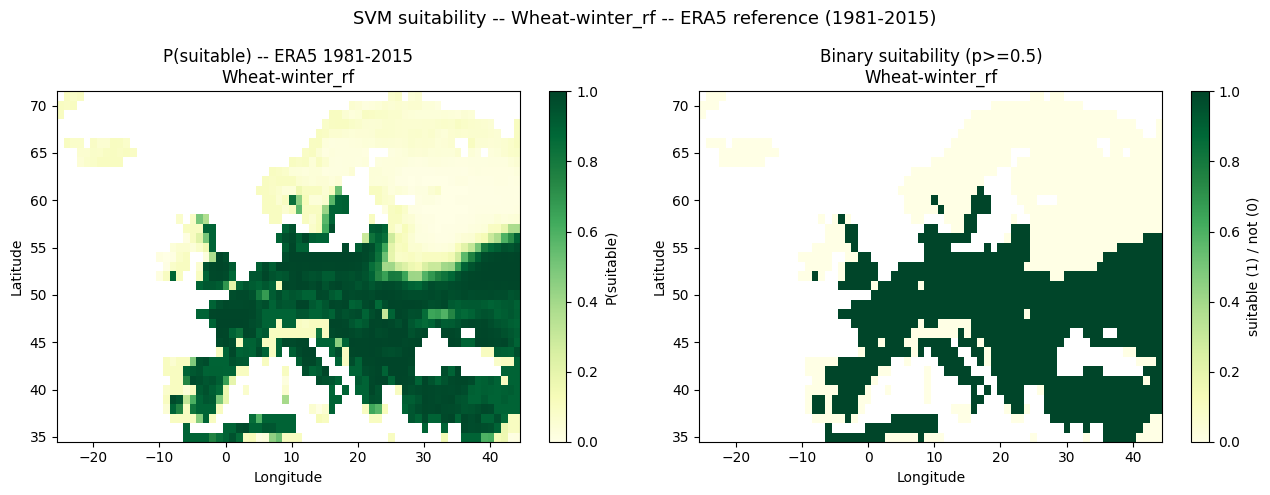

In [6]:
ext = [lons[0] - 0.5, lons[-1] + 0.5, lats[0] - 0.5, lats[-1] + 0.5]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im0 = axes[0].imshow(suit_proba, origin='lower', aspect='auto', extent=ext, cmap='YlGn', vmin=0, vmax=1)
axes[0].set_title(f'P(suitable) -- ERA5 1981-2015\n{CROP_LABEL}')
plt.colorbar(im0, ax=axes[0], label='P(suitable)')

im1 = axes[1].imshow(suit_bin, origin='lower', aspect='auto', extent=ext, cmap='YlGn', vmin=0, vmax=1)
axes[1].set_title(f'Binary suitability (p>={THRESHOLD})\n{CROP_LABEL}')
plt.colorbar(im1, ax=axes[1], label='suitable (1) / not (0)')

for ax in axes:
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
plt.suptitle(f'SVM suitability -- {CROP_LABEL} -- ERA5 reference (1981-2015)', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / f'suitability_ERA5_{CROP_LABEL}.png', dpi=150)
plt.show()

## 5. Suitable area (km² and Mha)

In [7]:
R_earth   = 6371.0
pixel_deg = 1.0
lat_area_km2   = (pixel_deg * np.pi / 180 * R_earth) ** 2 * np.cos(np.radians(lats))
pixel_area_km2 = np.tile(lat_area_km2[:, None], (1, nlon))
pixel_area_Mha = pixel_area_km2 * 100 / 1e6

mask = (suit_bin == 1) & ~np.isnan(suit_bin)
area_km2 = float(np.nansum(pixel_area_km2[mask]))
area_Mha = float(np.nansum(pixel_area_Mha[mask]))
print(f'=== Surface suitable (ERA5 1981-2015) -- {CROP_LABEL} ===')
print(f'  {area_km2:,.0f} km2  |  {area_Mha:.2f} Mha')

=== Surface suitable (ERA5 1981-2015) -- Wheat-winter_rf ===
  6,057,493 km2  |  605.75 Mha


## 6. Analyse par pays

Suitable area (ERA5 1981-2015) -- Wheat-winter_rf
    Country  Suitable_Mha
     France     51.655474
      Spain     30.086868
      Italy     20.989999
    Germany     33.391524
Netherlands      3.010652


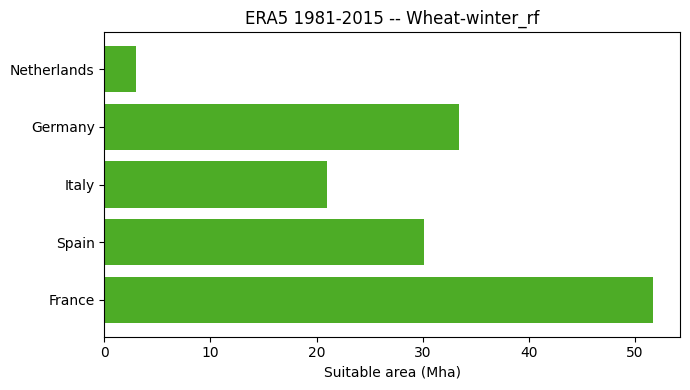

In [8]:
countries_rg = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
mask_da      = countries_rg.mask(lons, lats)
name_to_num  = {n: num for n, num in zip(countries_rg.names, countries_rg.numbers)}

rows = []
for name in COUNTRIES:
    c_num = name_to_num.get(name)
    if c_num is None:
        print(f'  WARNING: "{name}" not found in regionmask'); continue
    c_mask = (mask_da.values == c_num)
    a = float(np.nansum(pixel_area_Mha[(suit_bin == 1) & c_mask & ~np.isnan(suit_bin)]))
    rows.append({'Country': name, 'Suitable_Mha': a})

df_c = pd.DataFrame(rows)
print(f'Suitable area (ERA5 1981-2015) -- {CROP_LABEL}')
print(df_c.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(df_c['Country'], df_c['Suitable_Mha'], color='#4dac26')
ax.set_xlabel('Suitable area (Mha)')
ax.set_title(f'ERA5 1981-2015 -- {CROP_LABEL}')
plt.tight_layout()
plt.savefig(OUT_DIR / f'country_analysis_ERA5_{CROP_LABEL}.png', dpi=150)
plt.show()

## 7. Save

In [9]:
coords = {'lat': lats, 'lon': lons}
ds_out = xr.Dataset({
    'suit_proba': xr.DataArray(suit_proba, dims=['lat', 'lon'], coords=coords,
                               attrs={'long_name': 'SVM suitability probability, ERA5 1981-2015'}),
    'suit_bin':   xr.DataArray(suit_bin,   dims=['lat', 'lon'], coords=coords,
                               attrs={'long_name': 'Binary suitability', 'threshold': THRESHOLD}),
})
ds_out.attrs['description'] = f'SVM suitability -- {CROP_LABEL} -- ERA5 reference (1981-2015)'
ds_out.attrs['in_sample_auc'] = float(auc)
ds_out.attrs['in_sample_accuracy'] = float((tp + tn) / (tp + tn + fp + fn))

out_nc = OUT_DIR / f'suitability_ERA5_{CROP_LABEL}.nc'
ds_out.to_netcdf(out_nc)
print(f'Saved: {out_nc}')
print('Done.')

Saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\4_SVM_predict\svm_predict_outputs_ERA5_1deg\suitability_ERA5_Wheat-winter_rf.nc
Done.
